# Atividade em grupo 1 — Campanha de telemarketing bancário

Objetivo: prever se o cliente vai aderir ao depósito a prazo (`aderiu = sim`) **antes** de o operador ligar, para o banco priorizar os contatos com mais chance de adesão. Comparamos k-NN, Naive Bayes e regressão logística em dois cenários de atributos.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB, BernoulliNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,accuracy_score, precision_score, recall_score, f1_score,
                             roc_curve, roc_auc_score)

## 1. Análise exploratória

Leitura da base e conferência das dimensões (41.188 registros e 21 colunas, como no enunciado).

In [2]:
df = pd.read_csv("bank_marketing_completo.csv")
print("dimensões:", df.shape)
df.head()

dimensões: (41188, 21)


,idade,profissao,estado_civil,escolaridade,inadimplente,financiamento_imobiliario,emprestimo_pessoal,meio_contato,mes,dia_semana,...,contatos_campanha_atual,dias_desde_ultimo_contato,contatos_anteriores,resultado_campanha_anterior,taxa_variacao_emprego,indice_precos_consumidor,indice_confianca_consumidor,euribor_3m,numero_empregados,aderiu
0,56,empregado_domestico,casado,fundamental_4anos,nao,nao,nao,telefone_fixo,mai,seg,...,1,999,0,inexistente,1.1,93.994,-36.4,4.857,5191.0,nao
1,57,servicos,casado,ensino_medio,desconhecido,nao,nao,telefone_fixo,mai,seg,...,1,999,0,inexistente,1.1,93.994,-36.4,4.857,5191.0,nao
2,37,servicos,casado,ensino_medio,nao,sim,nao,telefone_fixo,mai,seg,...,1,999,0,inexistente,1.1,93.994,-36.4,4.857,5191.0,nao
3,40,administrativo,casado,fundamental_6anos,nao,nao,nao,telefone_fixo,mai,seg,...,1,999,0,inexistente,1.1,93.994,-36.4,4.857,5191.0,nao
4,56,servicos,casado,ensino_medio,nao,nao,sim,telefone_fixo,mai,seg,...,1,999,0,inexistente,1.1,93.994,-36.4,4.857,5191.0,nao


Tipos de dados e valores ausentes. Não há `NaN` na base, mas isso engana: os ausentes estão codificados como a categoria `desconhecido` e como o valor `999` em `dias_desde_ultimo_contato` (o máximo e a média dessa coluna mostram isso).

In [3]:
df.info()
print("\nausentes:", df.isna().sum().sum())
df.describe().T[["min", "max", "mean"]]

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   idade                        41188 non-null  int64  
 1   profissao                    41188 non-null  str    
 2   estado_civil                 41188 non-null  str    
 3   escolaridade                 41188 non-null  str    
 4   inadimplente                 41188 non-null  str    
 5   financiamento_imobiliario    41188 non-null  str    
 6   emprestimo_pessoal           41188 non-null  str    
 7   meio_contato                 41188 non-null  str    
 8   mes                          41188 non-null  str    
 9   dia_semana                   41188 non-null  str    
 10  duracao_ligacao_seg          41188 non-null  int64  
 11  contatos_campanha_atual      41188 non-null  int64  
 12  dias_desde_ultimo_contato    41188 non-null  int64  
 13  contatos_anteriores        

,min,max,mean
idade,17.000,98.000,40.024060
duracao_ligacao_seg,0.000,4918.000,258.285010
contatos_campanha_atual,1.000,56.000,2.567593
dias_desde_ultimo_contato,0.000,999.000,962.475454
contatos_anteriores,0.000,7.000,0.172963
taxa_variacao_emprego,-3.400,1.400,0.081886
indice_precos_consumidor,92.201,94.767,93.575664
indice_confianca_consumidor,-50.800,-26.900,-40.502600
euribor_3m,0.634,5.045,3.621291
numero_empregados,4963.600,5228.100,5167.035911


Distribuição da variável-alvo. A base é desbalanceada: só 11,3% dos contatos terminam em adesão. Um modelo que responda sempre `nao` acerta 88,7% das vezes sem identificar nenhum cliente, então a acurácia sozinha não serve para comparar os modelos.

aderiu
nao    36548
sim     4640
Name: count, dtype: int64
aderiu
nao    88.734583
sim    11.265417
Name: proportion, dtype: float64


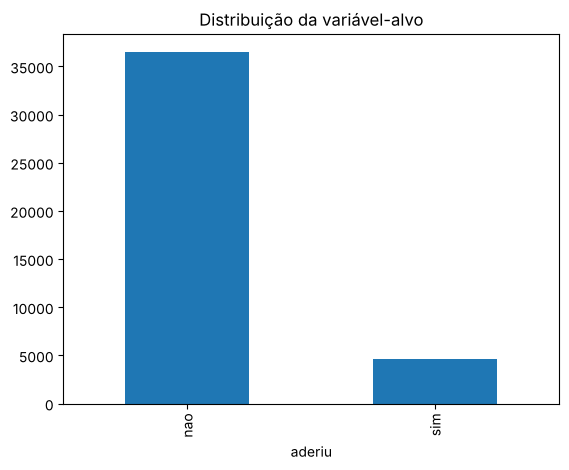

In [4]:
print(df["aderiu"].value_counts())
print(df["aderiu"].value_counts(normalize=True) * 100)
df["aderiu"].value_counts().plot(kind="bar")
plt.title("Distribuição da variável-alvo"); plt.show()

Qualidade da base. Pontos que exigem tratamento ou cuidado:

- 12 linhas duplicadas;
- `desconhecido` em seis colunas categóricas, principalmente em `inadimplente` (8.597 registros);
- `inadimplente` quase não varia: só 3 clientes com `sim`;
- `dias_desde_ultimo_contato` vale 999 em 96,3% das linhas, um código para "nunca foi contatado", e não uma quantidade de dias.

In [5]:
print("duplicadas:", df.duplicated().sum())
cat_cols = df.select_dtypes(exclude=[np.number]).columns.drop("aderiu")
print("\n'desconhecido' por coluna:")
print({c: int((df[c] == "desconhecido").sum()) for c in cat_cols if (df[c] == "desconhecido").any()})

print("\n% com dias_desde_ultimo_contato == 999:",
      round((df["dias_desde_ultimo_contato"] == 999).mean() * 100, 2))
print("\ninadimplente:\n", df["inadimplente"].value_counts())

duplicadas: 12

'desconhecido' por coluna:


{'profissao': 330, 'estado_civil': 80, 'escolaridade': 1731, 'inadimplente': 8597, 'financiamento_imobiliario': 990, 'emprestimo_pessoal': 990}

% com dias_desde_ultimo_contato == 999: 96.32

inadimplente:
 inadimplente
nao             32588
desconhecido     8597
sim                 3
Name: count, dtype: int64


Visualização 1: taxa de adesão por profissão. Estudantes (31%) e aposentados (25%) aderem bem mais que operários (7%) e trabalhadores de serviços (8%).

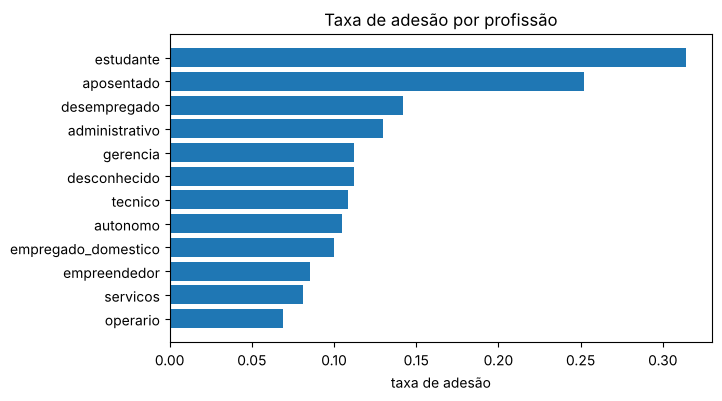

In [6]:
tmp = df.copy()
tmp["y"] = (tmp["aderiu"] == "sim").astype(int)
taxa = tmp.groupby("profissao")["y"].mean().sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(taxa.index, taxa.values)
ax.set_title("Taxa de adesão por profissão"); ax.set_xlabel("taxa de adesão")
plt.show()

Visualização 2: adesão por resultado da campanha anterior e por mês. Quem aderiu na campanha anterior adere de novo em 65% dos casos, contra 9% de quem nunca participou. Os meses de março, setembro, outubro e dezembro têm adesão acima de 40%, e maio (o mês com mais ligações) apenas 6%.

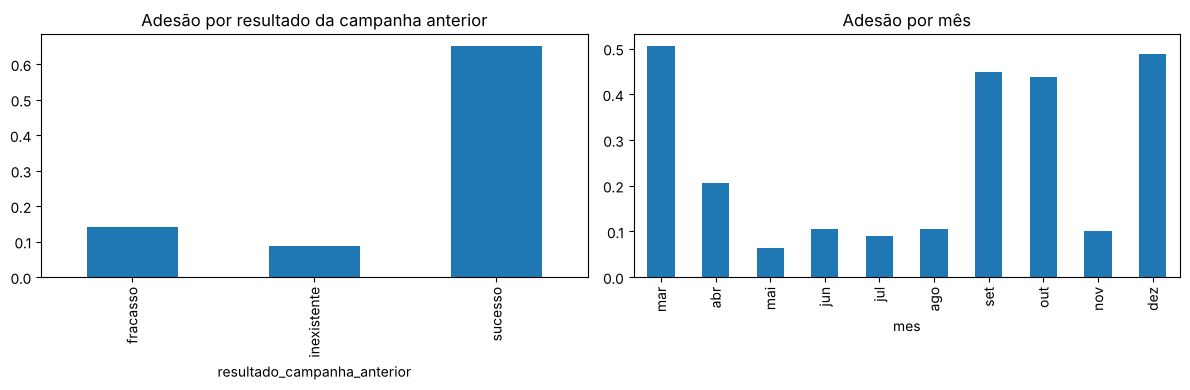

In [7]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
tmp.groupby("resultado_campanha_anterior")["y"].mean().plot(kind="bar", ax=eixos[0])
eixos[0].set_title("Adesão por resultado da campanha anterior")
ordem = ["mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]
tmp.groupby("mes")["y"].mean().reindex(ordem).plot(kind="bar", ax=eixos[1])
eixos[1].set_title("Adesão por mês")
plt.tight_layout(); plt.show()

Visualização 3: duração da ligação e Euribor por adesão. As ligações que terminam em adesão são bem mais longas (mediana de 449 s contra 164 s), e as adesões se concentram nos períodos de Euribor baixa. A duração, porém, só é conhecida depois que a ligação acontece (ver seção 4).

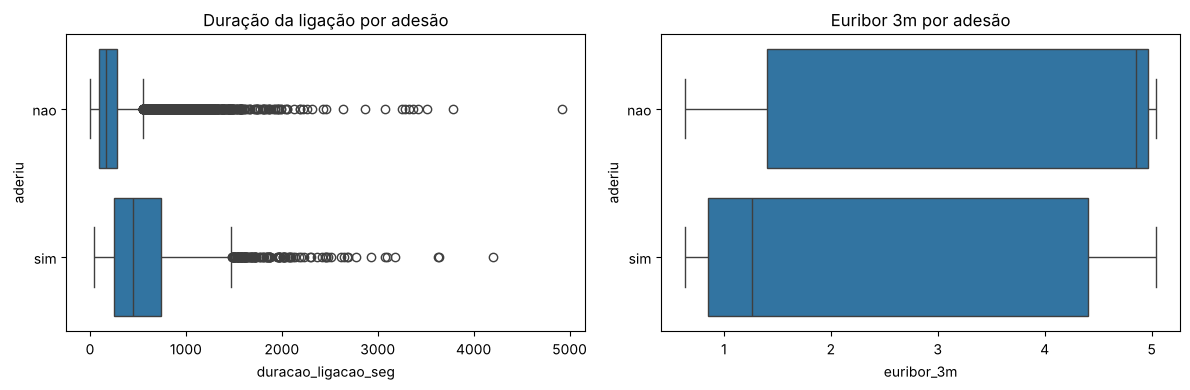

In [8]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x="duracao_ligacao_seg", y="aderiu", ax=eixos[0])
eixos[0].set_title("Duração da ligação por adesão")
sns.boxplot(data=df, x="euribor_3m", y="aderiu", ax=eixos[1])
eixos[1].set_title("Euribor 3m por adesão")
plt.tight_layout(); plt.show()

Visualização 4: três atributos que pesam em decisões tomadas mais adiante.

- **Meio de contato:** contatos por celular convertem 14,7%, contra 5,2% por telefone fixo.
- **Variação do emprego:** com variação abaixo de −1, a adesão passa de 35% em cinco dos seis valores; com variação positiva, fica entre 3% e 5%. É um retrato do contexto econômico, e não do cliente.
- **Contatos na campanha atual:** a adesão cai a cada nova tentativa, de 13,0% no primeiro contato para 3,1% a partir do décimo primeiro. Insistir rende pouco. Esse atributo inclui o contato que ainda vai ser feito, o que importa para a definição dos cenários (seção 2).

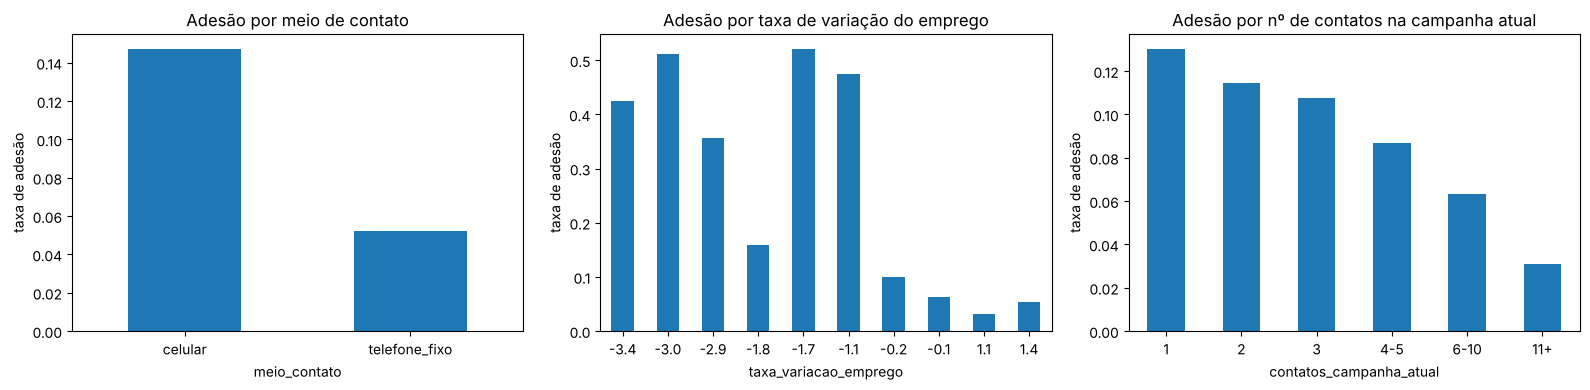

In [9]:
fig, eixos = plt.subplots(1, 3, figsize=(16, 4))
tmp.groupby("meio_contato")["y"].mean().plot(kind="bar", ax=eixos[0], rot=0)
eixos[0].set_title("Adesão por meio de contato")
tmp.groupby("taxa_variacao_emprego")["y"].mean().plot(kind="bar", ax=eixos[1], rot=0)
eixos[1].set_title("Adesão por taxa de variação do emprego")
faixas = pd.cut(tmp["contatos_campanha_atual"], [0, 1, 2, 3, 5, 10, 60],
                labels=["1", "2", "3", "4-5", "6-10", "11+"])
tmp.groupby(faixas, observed=True)["y"].mean().plot(kind="bar", ax=eixos[2], rot=0)
eixos[2].set_title("Adesão por nº de contatos na campanha atual")
for ax in eixos:
    ax.set_ylabel("taxa de adesão")
plt.tight_layout(); plt.show()

Dois pontos de qualidade vistos pelo lado da adesão, para decidir o tratamento:

- **Código 999:** quem já foi contatado em campanha anterior adere em 63,8% dos casos, contra 9,3% de quem nunca foi. Vale a pena guardar essa informação em um atributo próprio.
- **Categoria `desconhecido`:** em `inadimplente`, quem tem o dado desconhecido adere bem menos (5,2% contra 12,9%). Não saber o dado é informativo, o que justifica manter `desconhecido` como categoria em vez de tratá-lo como ausente.

In [10]:
print("taxa geral de adesão:", round(tmp["y"].mean() * 100, 2), "%")

ja_contatado = (tmp["dias_desde_ultimo_contato"] != 999).map({True: "ja contatado", False: "nunca contatado (999)"})
print("\nadesão conforme o contato em campanha anterior:")
print(tmp.groupby(ja_contatado)["y"].agg(["count", "mean"]).round(4))

linhas_desc = []
for c in cat_cols:
    if (tmp[c] == "desconhecido").any():
        desc = tmp[c] == "desconhecido"
        linhas_desc.append({"coluna": c, "qtd desconhecido": int(desc.sum()),
                            "adesão desconhecido (%)": tmp.loc[desc, "y"].mean() * 100,
                            "adesão demais (%)": tmp.loc[~desc, "y"].mean() * 100})
pd.DataFrame(linhas_desc).set_index("coluna").round(2)

taxa geral de adesão: 11.27 %

adesão conforme o contato em campanha anterior:
                           count    mean
dias_desde_ultimo_contato               
ja contatado                1515  0.6383
nunca contatado (999)      39673  0.0926


,qtd desconhecido,adesão desconhecido (%),adesão demais (%)
coluna,,,
profissao,330,11.21,11.27
estado_civil,80,15.00,11.26
escolaridade,1731,14.50,11.12
inadimplente,8597,5.15,12.88
financiamento_imobiliario,990,10.81,11.28
emprestimo_pessoal,990,10.81,11.28


Valores extremos. Há ligações de mais de uma hora (máximo de 4.918 s, com 99% abaixo de 1.271 s) e clientes contatados até 56 vezes (99% até 14). São registros reais, e não erros de digitação, então não foram removidos. A padronização reduz o efeito da escala, e a duração fica fora do cenário principal. As 4 ligações com duração zero terminaram todas sem adesão.

In [11]:
extremos = df[["duracao_ligacao_seg", "contatos_campanha_atual", "idade"]].describe(
    percentiles=[0.5, 0.95, 0.99]).T[["50%", "95%", "99%", "max"]]
print(extremos)
print("\nligações com duração 0 s:", int((df["duracao_ligacao_seg"] == 0).sum()),
      "| adesões entre elas:", int(((df["duracao_ligacao_seg"] == 0) & (df["aderiu"] == "sim")).sum()))

                           50%     95%      99%     max
duracao_ligacao_seg      180.0  752.65  1271.13  4918.0
contatos_campanha_atual    2.0    7.00    14.00    56.0
idade                     38.0   58.00    71.00    98.0

ligações com duração 0 s: 4 | adesões entre elas: 0


Visualização 5: correlação entre os atributos numéricos. Os indicadores macroeconômicos são fortemente correlacionados entre si (`euribor_3m`, `taxa_variacao_emprego` e `numero_empregados` acima de 0,9). Eles descrevem o momento do contato, e não o cliente, e essa redundância pesa na interpretação dos coeficientes da regressão logística.

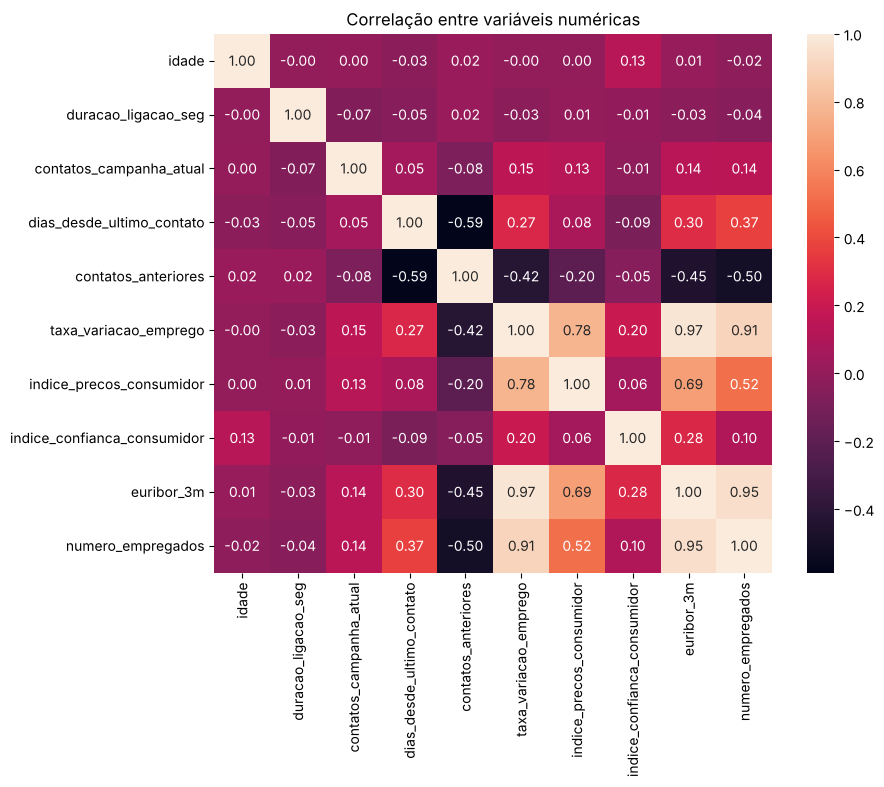

In [12]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f")
plt.title("Correlação entre variáveis numéricas"); plt.show()

## 2. Preparação dos dados

Alterações feitas na base e por quê:

- **Duplicadas removidas** (12 linhas), para o mesmo registro não aparecer no treino e no teste.
- **Alvo recodificado** para 0/1, com `sim` = 1 (classe positiva).
- **`foi_contatado_antes`**: novo atributo binário que guarda a informação contida no código 999.
- **999 vira ausente** em `dias_desde_ultimo_contato`. Mantido como número, o 999 distorceria as distâncias do k-NN. A imputação é feita depois, dentro do pipeline.
- **`desconhecido` é mantido** como uma categoria própria: não saber o dado também é informação, e excluir essas linhas eliminaria mais de 20% da base.

In [13]:
d = df.copy()
antes = len(d)
d = d.drop_duplicates().reset_index(drop=True)
print("duplicadas removidas:", antes - len(d))
d["aderiu"] = (d["aderiu"] == "sim").astype(int)
d["foi_contatado_antes"] = (d["dias_desde_ultimo_contato"] != 999).astype(int)
d.loc[d["dias_desde_ultimo_contato"] == 999, "dias_desde_ultimo_contato"] = np.nan
print("dimensões:", d.shape)

duplicadas removidas: 12
dimensões: (41176, 22)


Divisão em treino (70%) e teste (30%), estratificada pelo alvo e com `random_state=42`, como pede o enunciado. A proporção de `sim` fica igual nos dois conjuntos. O teste só volta a ser usado na avaliação final.

In [14]:
X = d.drop(columns="aderiu")
y = d["aderiu"]
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)
print("treino:", X_treino.shape, "| teste:", X_teste.shape)
print("proporção de 'sim' -> treino:", round(y_treino.mean(), 4), "| teste:", round(y_teste.mean(), 4))

treino: (28823, 21) | teste: (12353, 21)
proporção de 'sim' -> treino: 0.1127 | teste: 0.1127


Cenários de avaliação. No **cenário principal** ficam só os atributos disponíveis antes de o banco decidir para quem ligar. Excluímos:

- `duracao_ligacao_seg`: só existe depois que a ligação termina;
- `contatos_campanha_atual`: inclui o contato que ainda vai ser feito.

O **cenário completo** usa todos os atributos, apenas para comparação.

In [15]:
cols_excluidas = ["duracao_ligacao_seg", "contatos_campanha_atual"]
cols_completo = X_treino.columns.tolist()
cols_principal = [c for c in cols_completo if c not in cols_excluidas]
print("principal:", len(cols_principal), "atributos | completo:", len(cols_completo))

principal: 19 atributos | completo: 21


Pré-processamento em `Pipeline`, igual para os três algoritmos: mediana e padronização (`StandardScaler`) nos atributos numéricos, e moda e one-hot nos categóricos. Como tudo está dentro do pipeline, as medianas, médias e desvios são calculados só com os dados de treino de cada ajuste, sem vazamento do teste nem das partições de validação. A padronização é indispensável para o k-NN, que depende de distâncias.

In [16]:
def montar_prep(cols):
    num = X_treino[cols].select_dtypes(include=[np.number]).columns.tolist()
    cat = X_treino[cols].select_dtypes(exclude=[np.number]).columns.tolist()
    pipe_num = Pipeline([("imputador", SimpleImputer(strategy="median")),
                         ("escala", StandardScaler())])
    pipe_cat = Pipeline([("imputador", SimpleImputer(strategy="most_frequent")),
                         ("onehot", OneHotEncoder(handle_unknown="ignore"))])
    return ColumnTransformer([("num", pipe_num, num),
                              ("cat", pipe_cat, cat)])

## 3. Modelagem

### 3.1 Escolha dos hiperparâmetros

A busca é feita por validação cruzada em uma amostra estratificada de 8.000 registros **do treino** (o enunciado permite, pelo tamanho da base). O conjunto de teste não participa.

In [17]:
X_busca, _, y_busca, _ = train_test_split(
    X_treino, y_treino, train_size=8000, random_state=42, stratify=y_treino)
print("amostra da busca:", X_busca.shape, "| proporção de 'sim':", round(y_busca.mean(), 4))

amostra da busca: (8000, 21) | proporção de 'sim': 0.1126


Busca do `k` do k-NN e do `C` da regressão logística, com 5 partições e F1 da classe `sim` como critério (justificativa na seção 4).

O melhor `C` ficou no limite superior da grade (1000), ou seja, quase sem regularização. O F1 praticamente não muda a partir de `C = 1`, então a escolha tem pouco efeito sobre o desempenho.

In [18]:
METRICA = "f1"
melhores = {}
for nome_cen, cols in [("principal", cols_principal), ("completo", cols_completo)]:
    pipe_knn = Pipeline([("prep", montar_prep(cols)),
                         ("knn", KNeighborsClassifier())])
    gs_knn = GridSearchCV(pipe_knn,
                          {"knn__n_neighbors": [1, 3, 5, 7, 9, 11, 15, 21, 31, 51]},
                          cv=5, scoring=METRICA, n_jobs=-1)
    gs_knn.fit(X_busca[cols], y_busca)
    pipe_lr = Pipeline([("prep", montar_prep(cols)),
                        ("lr", LogisticRegression(max_iter=1000, random_state=42))])
    gs_lr = GridSearchCV(pipe_lr,
                         {"lr__C": [0.001, 0.01, 0.1, 1, 10, 100, 1000]},
                         cv=5, scoring=METRICA, n_jobs=-1)
    gs_lr.fit(X_busca[cols], y_busca)
    melhores[nome_cen] = {"k": gs_knn.best_params_["knn__n_neighbors"],
                          "C": gs_lr.best_params_["lr__C"]}
    print(f"[{nome_cen}] k = {melhores[nome_cen]['k']} (F1 CV = {gs_knn.best_score_:.4f}) | "
          f"C = {melhores[nome_cen]['C']} (F1 CV = {gs_lr.best_score_:.4f})")
    print("   F1 por C:", dict(zip([0.001, 0.01, 0.1, 1, 10, 100, 1000],
                                   gs_lr.cv_results_["mean_test_score"].round(3))))

[principal] k = 15 (F1 CV = 0.3542) | C = 1000 (F1 CV = 0.3510)
   F1 por C: {0.001: np.float64(0.239), 0.01: np.float64(0.319), 0.1: np.float64(0.334), 1: np.float64(0.345), 10: np.float64(0.347), 100: np.float64(0.349), 1000: np.float64(0.351)}


[completo] k = 3 (F1 CV = 0.4637) | C = 1000 (F1 CV = 0.5100)
   F1 por C: {0.001: np.float64(0.266), 0.01: np.float64(0.451), 0.1: np.float64(0.494), 1: np.float64(0.509), 10: np.float64(0.508), 100: np.float64(0.509), 1000: np.float64(0.51)}


Naive Bayes: escolha da variante. Depois da preparação, a base tem atributos numéricos padronizados e atributos binários (one-hot). Comparamos duas variantes sobre a mesma preparação:

- **`GaussianNB`**: supõe distribuição normal para cada atributo. É adequada aos numéricos e uma aproximação para os binários.
- **`BernoulliNB`**: adequada aos binários. Os numéricos são binarizados em "acima ou abaixo da média", o que perde informação.

A `CategoricalNB` foi descartada porque exigiria outra preparação (discretizar os numéricos e codificar as categorias como inteiros), e o enunciado pede a mesma preparação para os três classificadores.

A variante é escolhida pelo F1 da validação cruzada, na mesma amostra da busca anterior.

In [19]:
variantes_nb = {"GaussianNB": GaussianNB, "BernoulliNB": BernoulliNB}
for nome_cen, cols in [("principal", cols_principal), ("completo", cols_completo)]:
    f1_nb = {}
    for nome_nb, classe_nb in variantes_nb.items():
        # sparse_threshold=0 devolve matriz densa, exigida pelo GaussianNB
        pipe_nb = Pipeline([("prep", montar_prep(cols).set_params(sparse_threshold=0)),
                            ("nb", classe_nb())])
        f1_nb[nome_nb] = cross_val_score(pipe_nb, X_busca[cols], y_busca,
                                         cv=5, scoring=METRICA, n_jobs=-1).mean()
    melhores[nome_cen]["nb"] = max(f1_nb, key=f1_nb.get)
    print(f"[{nome_cen}] GaussianNB (F1 CV = {f1_nb['GaussianNB']:.4f}) | "
          f"BernoulliNB (F1 CV = {f1_nb['BernoulliNB']:.4f}) | escolhida: {melhores[nome_cen]['nb']}")

[principal] GaussianNB (F1 CV = 0.4102) | BernoulliNB (F1 CV = 0.3995) | escolhida: GaussianNB


[completo] GaussianNB (F1 CV = 0.4496) | BernoulliNB (F1 CV = 0.4340) | escolhida: GaussianNB


### 3.2 Modelos finais

Cada modelo é treinado no conjunto de treino **completo** (28.823 registros), com os hiperparâmetros escolhidos acima, e só então faz as previsões para o teste.

In [20]:
def montar_modelos(nome_cen):
    m = melhores[nome_cen]
    return {"k-NN": KNeighborsClassifier(n_neighbors=m["k"]),
            "Naive Bayes": variantes_nb[m["nb"]](),
            "Regressão logística": LogisticRegression(C=m["C"], max_iter=1000, random_state=42)}

modelos, previsoes = {}, {}
for nome_cen, cols in [("principal", cols_principal), ("completo", cols_completo)]:
    for nome_mod, clf in montar_modelos(nome_cen).items():
        pipe = Pipeline([("prep", montar_prep(cols).set_params(sparse_threshold=0)),
                         ("clf", clf)])
        pipe.fit(X_treino[cols], y_treino)
        modelos[(nome_cen, nome_mod)] = pipe
        previsoes[(nome_cen, nome_mod)] = pipe.predict(X_teste[cols])
        print(f"[{nome_cen}] {nome_mod} treinado: {clf}")

[principal] k-NN treinado: KNeighborsClassifier(n_neighbors=15)
[principal] Naive Bayes treinado: GaussianNB()


[principal] Regressão logística treinado: LogisticRegression(C=1000, max_iter=1000, random_state=42)


[completo] k-NN treinado: KNeighborsClassifier(n_neighbors=3)
[completo] Naive Bayes treinado: GaussianNB()


[completo] Regressão logística treinado: LogisticRegression(C=1000, max_iter=1000, random_state=42)


Coeficientes da regressão logística: os cinco de maior magnitude no cenário principal. Como os numéricos estão padronizados, o coeficiente indica o efeito de um desvio-padrão do atributo. Nos categóricos, indica o efeito de pertencer àquela categoria. Sinal positivo aumenta a chance de adesão.

In [21]:
pipe_lr = modelos[("principal", "Regressão logística")]
coefs = pd.Series(pipe_lr.named_steps["clf"].coef_[0],
                  index=pipe_lr.named_steps["prep"].get_feature_names_out())
top5 = coefs.loc[coefs.abs().sort_values(ascending=False).index[:5]]
pd.DataFrame({"coeficiente": top5, "razao_de_chances": np.exp(top5)}).round(3)

,coeficiente,razao_de_chances
num__taxa_variacao_emprego,-2.328,0.097
cat__mes_mar,1.282,3.606
num__indice_precos_consumidor,1.118,3.060
cat__mes_jun,-0.790,0.454
cat__meio_contato_telefone_fixo,-0.688,0.503


Interpretação:

- **`taxa_variacao_emprego` (negativo, o maior):** quanto mais aquecido o mercado de trabalho, menor a adesão. As adesões se concentram no período de crise.
- **`mes_mar` (positivo):** ligações feitas em março convertem muito mais, o que confirma o gráfico de adesão por mês.
- **`indice_precos_consumidor` (positivo):** inflação mais alta aparece associada a mais adesão, mantidos os demais atributos.
- **`mes_jun` (negativo):** junho converte menos que os outros meses, descontado o efeito dos indicadores econômicos.
- **`meio_contato_telefone_fixo` (negativo):** contatos por telefone fixo convertem menos que por celular.

Quase todos descrevem **o momento do contato**, e não o cliente. Os indicadores macroeconômicos são muito correlacionados entre si e o `C` escolhido quase não regulariza, então o valor individual desses coeficientes é instável e deve ser lido com cautela.

## 4. Avaliação

Métricas no conjunto de teste, para cada modelo e cenário: acurácia e precisão, recall e F1 por classe. A linha de base (prever sempre `nao`) entra como referência.

**Métrica principal: F1 da classe `sim`.** Com 88,7% de `nao`, um modelo que nunca indicasse ninguém teria 88,7% de acurácia, então a acurácia não serve como critério. O que interessa ao banco é a classe positiva: o recall mede quantos dos clientes que aderem o modelo encontra, e a precisão mede quantas das ligações indicadas resultam em adesão. O F1 combina as duas e penaliza o modelo que só vai bem em uma delas.

In [22]:
def calcular_metricas(y_real, y_prev):
    return {"acuracia": accuracy_score(y_real, y_prev),
            "precisao_nao": precision_score(y_real, y_prev, pos_label=0, zero_division=0),
            "recall_nao": recall_score(y_real, y_prev, pos_label=0, zero_division=0),
            "f1_nao": f1_score(y_real, y_prev, pos_label=0, zero_division=0),
            "precisao_sim": precision_score(y_real, y_prev, pos_label=1, zero_division=0),
            "recall_sim": recall_score(y_real, y_prev, pos_label=1, zero_division=0),
            "f1_sim": f1_score(y_real, y_prev, pos_label=1, zero_division=0)}

# linha de base: prever sempre a classe majoritária ("nao")
linhas = [{"cenario": "-", "modelo": "Linha de base (sempre nao)",
           **calcular_metricas(y_teste, np.zeros(len(y_teste), dtype=int))}]
for (nome_cen, nome_mod), y_prev in previsoes.items():
    linhas.append({"cenario": nome_cen, "modelo": nome_mod, **calcular_metricas(y_teste, y_prev)})
    print(f"===== {nome_mod} | cenário {nome_cen} =====")
    print(classification_report(y_teste, y_prev, target_names=["nao", "sim"], digits=4))
resultados = pd.DataFrame(linhas)

===== k-NN | cenário principal =====
              precision    recall  f1-score   support

         nao     0.9108    0.9802    0.9442     10961
         sim     0.6104    0.2443    0.3489      1392

    accuracy                         0.8973     12353
   macro avg     0.7606    0.6122    0.6466     12353
weighted avg     0.8770    0.8973    0.8772     12353

===== Naive Bayes | cenário principal =====


              precision    recall  f1-score   support

         nao     0.9413    0.8605    0.8991     10961
         sim     0.3446    0.5776    0.4317      1392

    accuracy                         0.8286     12353
   macro avg     0.6430    0.7190    0.6654     12353
weighted avg     0.8741    0.8286    0.8464     12353

===== Regressão logística | cenário principal =====
              precision    recall  f1-score   support

         nao     0.9081    0.9861    0.9455     10961
         sim     0.6622    0.2141    0.3236      1392

    accuracy                         0.8991     12353
   macro avg     0.7852    0.6001    0.6345     12353
weighted avg     0.8804    0.8991    0.8754     12353

===== k-NN | cenário completo =====
              precision    recall  f1-score   support

         nao     0.9301    0.9567    0.9432     10961
         sim     0.5598    0.4339    0.4889      1392

    accuracy                         0.8978     12353
   macro avg     0.7449    0.6953    0.7

===== Regressão logística | cenário completo =====
              precision    recall  f1-score   support

         nao     0.9295    0.9713    0.9499     10961
         sim     0.6500    0.4203    0.5105      1392

    accuracy                         0.9092     12353
   macro avg     0.7898    0.6958    0.7302     12353
weighted avg     0.8980    0.9092    0.9004     12353



Matrizes de confusão no teste. Linhas são a classe real, colunas a classe prevista.

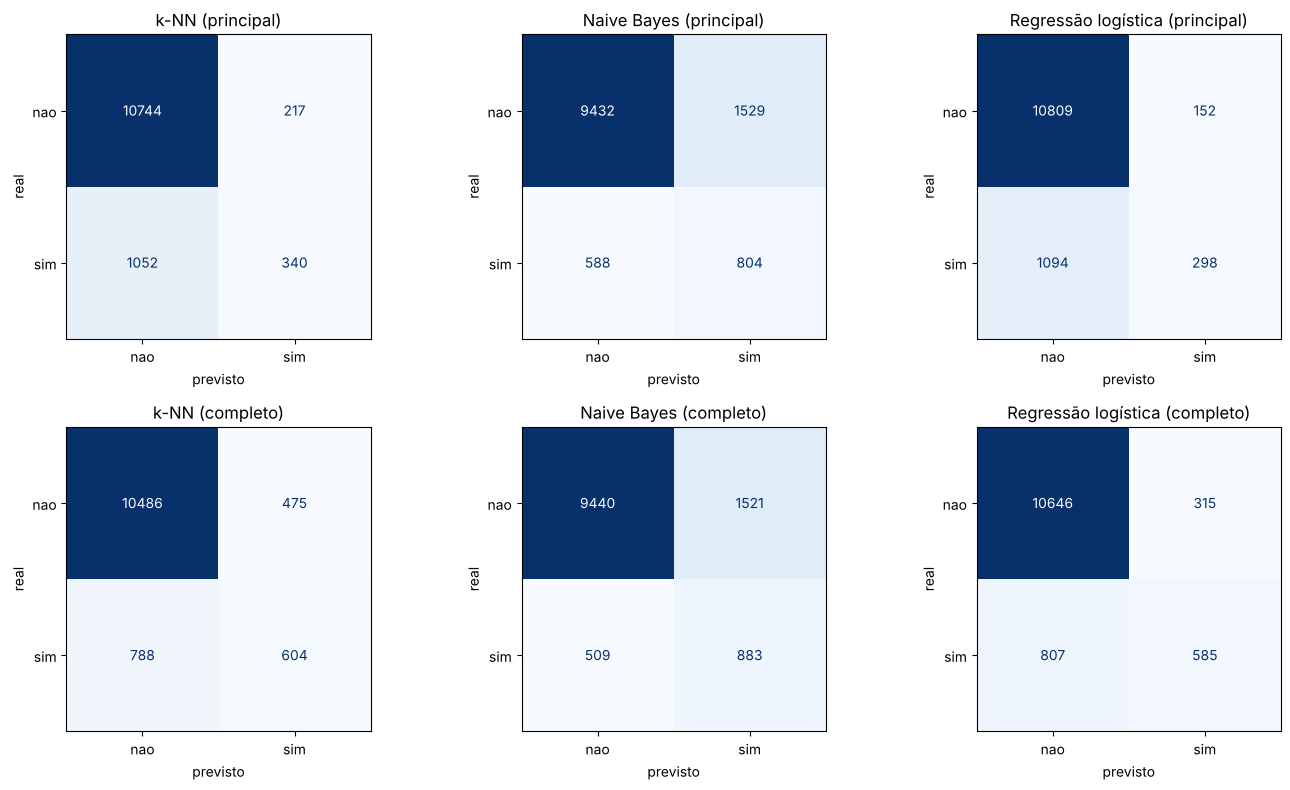

In [23]:
fig, eixos = plt.subplots(2, 3, figsize=(14, 8))
for i, nome_cen in enumerate(["principal", "completo"]):
    for j, nome_mod in enumerate(["k-NN", "Naive Bayes", "Regressão logística"]):
        cm = confusion_matrix(y_teste, previsoes[(nome_cen, nome_mod)])
        ConfusionMatrixDisplay(cm, display_labels=["nao", "sim"]).plot(
            ax=eixos[i, j], cmap="Blues", colorbar=False, values_format="d")
        eixos[i, j].set_title(f"{nome_mod} ({nome_cen})")
        eixos[i, j].set_xlabel("previsto"); eixos[i, j].set_ylabel("real")
plt.tight_layout(); plt.show()

### 4.1 Curva ROC e AUC

As métricas acima valem só para o limiar padrão de 0,5. A curva ROC mostra o modelo em todos os limiares: cada ponto é uma matriz de confusão, com a taxa de falsos positivos (dos que não aderem, quantos o modelo indicou à toa) no eixo horizontal e a taxa de verdadeiros positivos (o recall) no vertical. A AUC resume a curva em um número: a chance de o modelo dar probabilidade maior a um cliente que adere do que a um que não adere. Vale 0,5 para o chute aleatório e 1,0 para o modelo perfeito.

A AUC é calculada com `predict_proba`, e não com a classe prevista.

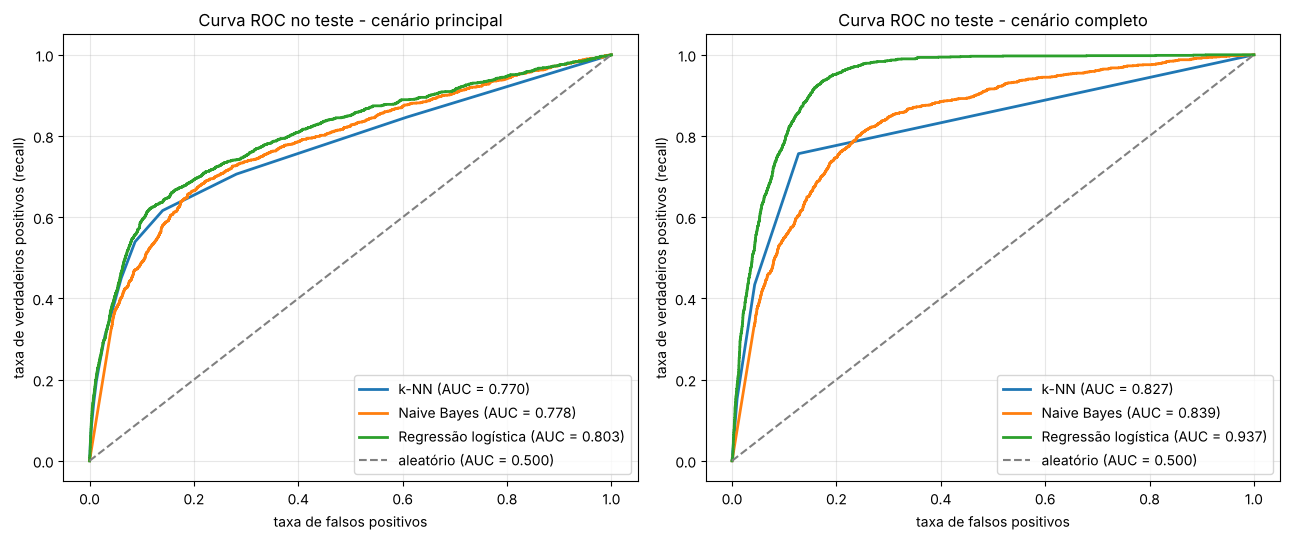

In [24]:
# probabilidade da classe positiva ("sim") para cada cliente do teste
probabilidades = {chave: pipe.predict_proba(X_teste[cols_principal if chave[0] == "principal" else cols_completo])[:, 1]
                  for chave, pipe in modelos.items()}

fig, eixos = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, nome_cen in zip(eixos, ["principal", "completo"]):
    for nome_mod in ["k-NN", "Naive Bayes", "Regressão logística"]:
        proba = probabilidades[(nome_cen, nome_mod)]
        tfp, tvp, limiares = roc_curve(y_teste, proba)
        ax.plot(tfp, tvp, linewidth=2, label=f"{nome_mod} (AUC = {roc_auc_score(y_teste, proba):.3f})")
    ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="aleatório (AUC = 0.500)")
    ax.set_title(f"Curva ROC no teste - cenário {nome_cen}")
    ax.set_xlabel("taxa de falsos positivos"); ax.set_ylabel("taxa de verdadeiros positivos (recall)")
    ax.legend(loc="lower right"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

resultados["auc"] = [0.5 if c == "-" else roc_auc_score(y_teste, probabilidades[(c, m)])
                     for c, m in zip(resultados["cenario"], resultados["modelo"])]

No cenário principal, a regressão logística tem a maior AUC (0,803), seguida do Naive Bayes (0,778) e do k-NN (0,770). A ordem é diferente da do F1 em 0,5: a logística é a que melhor ordena os clientes por chance de adesão, mesmo tendo o menor recall no limiar padrão.

No cenário completo, a AUC da logística chega a 0,937. Um valor tão alto é sinal de informação do alvo nos atributos, e é o caso: a duração da ligação só existe depois do contato.

Análise do limiar no cenário principal: o que acontece com cada modelo quando o limiar baixa.

In [25]:
linhas_lim = []
for nome_mod in ["k-NN", "Naive Bayes", "Regressão logística"]:
    proba = probabilidades[("principal", nome_mod)]
    for limiar in [0.5, 0.3, 0.2, 0.1]:
        y_lim = (proba >= limiar).astype(int)
        vn, fp, fn, vp = confusion_matrix(y_teste, y_lim).ravel()
        linhas_lim.append({"modelo": nome_mod, "limiar": limiar, "VP": vp, "FN": fn, "FP": fp,
                           "recall (TVP)": vp / (vp + fn), "TFP": fp / (fp + vn),
                           "precisao": vp / (vp + fp), "f1": f1_score(y_teste, y_lim)})
pd.DataFrame(linhas_lim).set_index(["modelo", "limiar"]).round(3)

VP    FN    FP  recall (TVP)    TFP  precisao  \
modelo              limiar                                                   
k-NN                0.5     340  1052   217         0.244  0.020     0.610   
                    0.3     627   765   667         0.450  0.061     0.485   
                    0.2     858   534  1535         0.616  0.140     0.359   
                    0.1     983   409  3086         0.706  0.282     0.242   
Naive Bayes         0.5     804   588  1529         0.578  0.139     0.345   
                    0.3     839   553  1696         0.603  0.155     0.331   
                    0.2     854   538  1812         0.614  0.165     0.320   
                    0.1     894   498  1959         0.642  0.179     0.313   
Regressão logística 0.5     298  1094   152         0.214  0.014     0.662   
                    0.3     587   805   587         0.422  0.054     0.500   
                    0.2     786   606  1004         0.565  0.092     0.439   
                    0.1     941   451  1958         0.676  0.179     0.325   

                               f1  
modelo              limiar         
k-NN                0.5     0.349  
                    0.3     0.467  
                    0.2     0.453  
                    0.1     0.360  
Naive Bayes         0.5     0.432  
                    0.3     0.427  
                    0.2     0.421  
                    0.1     0.421  
Regressão logística 0.5     0.324  
                    0.3     0.458  
                    0.2     0.494  
                    0.1     0.439

Baixar o limiar aumenta o recall e a taxa de falsos positivos ao mesmo tempo. A regressão logística com limiar 0,2 encontra 56,5% dos clientes que aderem, com precisão de 43,9% e F1 de 0,494, acima do melhor resultado do Naive Bayes (0,432). As probabilidades do Naive Bayes ficam concentradas perto de 0 e de 1, por isso ele quase não muda com o limiar.

Essa tabela usa o conjunto de teste apenas para ilustrar o efeito. A escolha de um limiar para uso real teria de ser feita com dados de treino e validação, e depende do custo de cada erro para o banco.

Validação cruzada estratificada com 5 partições sobre o conjunto de treino, no cenário principal, com média e desvio-padrão do F1 e da AUC de cada modelo.

In [26]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_f1, cv_auc = {}, {}
for nome_mod, clf in montar_modelos("principal").items():
    pipe = Pipeline([("prep", montar_prep(cols_principal).set_params(sparse_threshold=0)),
                     ("clf", clf)])
    notas = cross_val_score(pipe, X_treino[cols_principal], y_treino,
                            cv=cv, scoring=METRICA, n_jobs=-1)
    notas_auc = cross_val_score(pipe, X_treino[cols_principal], y_treino,
                                cv=cv, scoring="roc_auc", n_jobs=-1)
    cv_f1[nome_mod] = (notas.mean(), notas.std())
    cv_auc[nome_mod] = (notas_auc.mean(), notas_auc.std())
    print(f"{nome_mod}: F1 por partição = {notas.round(4)} | "
          f"média = {notas.mean():.4f} | desvio-padrão = {notas.std():.4f}")
    print(f"{' ' * len(nome_mod)}  AUC por partição = {notas_auc.round(4)} | "
          f"média = {notas_auc.mean():.4f} | desvio-padrão = {notas_auc.std():.4f}")

k-NN: F1 por partição = [0.3484 0.3462 0.372  0.3615 0.3859] | média = 0.3628 | desvio-padrão = 0.0148
      AUC por partição = [0.7618 0.7551 0.7682 0.7338 0.7575] | média = 0.7553 | desvio-padrão = 0.0116


Naive Bayes: F1 por partição = [0.4023 0.4118 0.4262 0.3865 0.4092] | média = 0.4072 | desvio-padrão = 0.0130
             AUC por partição = [0.7701 0.764  0.7824 0.7458 0.7543] | média = 0.7633 | desvio-padrão = 0.0126


Regressão logística: F1 por partição = [0.3237 0.323  0.3485 0.3417 0.3777] | média = 0.3429 | desvio-padrão = 0.0200
                     AUC por partição = [0.796  0.786  0.7999 0.7685 0.782 ] | média = 0.7865 | desvio-padrão = 0.0111


Tabela comparativa única: métricas no teste para os dois cenários, e F1 e AUC da validação cruzada (média e desvio-padrão) para o cenário principal.

In [27]:
for nome_col, notas_cv in [("f1_cv", cv_f1), ("auc_cv", cv_auc)]:
    resultados[nome_col + "_media"] = [notas_cv[m][0] if c == "principal" else np.nan
                                       for c, m in zip(resultados["cenario"], resultados["modelo"])]
    resultados[nome_col + "_desvio"] = [notas_cv[m][1] if c == "principal" else np.nan
                                        for c, m in zip(resultados["cenario"], resultados["modelo"])]
resultados.set_index(["cenario", "modelo"]).round(4)

acuracia  precisao_nao  recall_nao  \
cenario   modelo                                                           
-         Linha de base (sempre nao)    0.8873        0.8873      1.0000   
principal k-NN                          0.8973        0.9108      0.9802   
          Naive Bayes                   0.8286        0.9413      0.8605   
          Regressão logística           0.8991        0.9081      0.9861   
completo  k-NN                          0.8978        0.9301      0.9567   
          Naive Bayes                   0.8357        0.9488      0.8612   
          Regressão logística           0.9092        0.9295      0.9713   

                                      f1_nao  precisao_sim  recall_sim  \
cenario   modelo                                                         
-         Linha de base (sempre nao)  0.9403        0.0000      0.0000   
principal k-NN                        0.9442        0.6104      0.2443   
          Naive Bayes                 0.8991        0.3446      0.5776   
          Regressão logística         0.9455        0.6622      0.2141   
completo  k-NN                        0.9432        0.5598      0.4339   
          Naive Bayes                 0.9029        0.3673      0.6343   
          Regressão logística         0.9499        0.6500      0.4203   

                                      f1_sim     auc  f1_cv_media  \
cenario   modelo                                                    
-         Linha de base (sempre nao)  0.0000  0.5000          NaN   
principal k-NN                        0.3489  0.7700       0.3628   
          Naive Bayes                 0.4317  0.7783       0.4072   
          Regressão logística         0.3236  0.8033       0.3429   
completo  k-NN                        0.4889  0.8270          NaN   
          Naive Bayes                 0.4652  0.8393          NaN   
          Regressão logística         0.5105  0.9369          NaN   

                                      f1_cv_desvio  auc_cv_media  \
cenario   modelo                                                   
-         Linha de base (sempre nao)           NaN           NaN   
principal k-NN                              0.0148        0.7553   
          Naive Bayes                       0.0130        0.7633   
          Regressão logística               0.0200        0.7865   
completo  k-NN                                 NaN           NaN   
          Naive Bayes                          NaN           NaN   
          Regressão logística                  NaN           NaN   

                                      auc_cv_desvio  
cenario   modelo                                     
-         Linha de base (sempre nao)            NaN  
principal k-NN                               0.0116  
          Naive Bayes                        0.0126  
          Regressão logística                0.0111  
completo  k-NN                                  NaN  
          Naive Bayes                           NaN  
          Regressão logística                   NaN

Leitura da tabela:

- **No limiar padrão de 0,5**, o Naive Bayes tem o maior F1 da classe `sim` no cenário principal (0,432), no teste e na validação cruzada. Todos os modelos superam a linha de base em F1, mas só k-NN e regressão logística a superam em acurácia, e por cerca de um ponto percentual.
- **Pela AUC**, a regressão logística é a melhor no teste (0,803) e na validação cruzada (0,787 ± 0,011, contra 0,763 ± 0,013 do Naive Bayes). A diferença é de cerca de dois desvios-padrão.
- As duas leituras são verdadeiras ao mesmo tempo: o Naive Bayes é o melhor *no corte 0,5*, e a regressão logística é a que melhor *ordena* os clientes e a que mais ganha com o ajuste do limiar.
- **No cenário completo** tudo melhora por causa da duração da ligação, que não existe antes do contato.